# Reto S08 · «Duelo de modelos» · TurisData Canarias

**Equipo de ejemplo (Solucionario).** Parte de `S08_06_leaderboard_plantilla`: las herramientas no se tocan; se rellenan los `TODO`, se añaden las búsquedas y se deja ejecutado de arriba abajo (*Reiniciar y ejecutar todo*).

## Qué hay en este cuaderno

1. Datos y partición (el test no se mira hasta el final).
2. Herramientas del *leaderboard* (sin cambios).
3. Ocho modelos de seis familias, dos de ellos ajustados con búsqueda.
4. Pesos acordados con el cliente y análisis de sensibilidad.
5. Examen final: AUC en test **solo del campeón**, una vez.

**Salidas:** `leaderboard_S08.csv` y las cifras de `model_card.md`.

In [1]:
# Preparación (ejecuta esta celda siempre la primera)
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta


In [2]:
import os
import pickle
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score
import lightgbm as lgb
from scipy.stats import randint, loguniform, uniform   # generadores de valores para las búsquedas aleatorias (paso 3 del reto)

warnings.filterwarnings("ignore")
SEMILLA = 42
SEMILLA_TEST = 7                      # partición propia del reto: distinta de la de las prácticas S08_01 a S08_05 (test que no habéis visto)
sns.set_theme(style="whitegrid")

RUTA_CSV = "leaderboard_S08.csv"     # el leaderboard se guarda aquí (en la carpeta del notebook)
REINICIAR = True                      # True = empieza de cero al ejecutar todo; False = conserva lo registrado

## 1. Datos y partición

Mismo problema que en las prácticas: predecir `cancelada`. El **test se reserva** hasta el final; todas las
comparaciones del leaderboard se hacen con **validación cruzada sobre train** (5 folds). La partición es **otra** distinta de la de
`S08_01` a `S08_05` (`SEMILLA_TEST`): en esas prácticas mirabais el test para aprender; este, el del reto, no lo habéis visto.

In [3]:
df = pd.read_csv(dato("reservas_turisdata.csv"), parse_dates=["fecha_reserva", "fecha_llegada"])
df["temporada_alta"] = df["fecha_llegada"].dt.month.isin([1, 2, 3, 7, 8, 12]).astype(int)
columnas_num = ["antelacion_dias", "noches", "adultos", "ninos", "precio_noche",
                "peticiones_especiales", "cliente_repetidor", "cancelaciones_previas", "temporada_alta"]
columnas_cat = ["tipo_habitacion", "regimen", "canal", "pais_origen", "tarifa", "deposito"]
X, y = df[columnas_num + columnas_cat], df["cancelada"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA_TEST, stratify=y)
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
print(f"Train: {len(X_train)} · Test (intacto hasta el final): {len(X_test)}")

Train: 4800 · Test (intacto hasta el final): 1200


## 2. Herramientas del leaderboard (no modificar)

- `hacer_pipe(clasificador, escalar)`: preprocesado estándar + el clasificador que le pases.
- `evaluar_modelo(...)`: mide **AUC y AP (validación cruzada)**, **tiempo de ajuste**, **tiempo de predicción
  por cada 1000 reservas** y **tamaño del modelo** en KB. La **explicabilidad** (1 = caja negra, 5 = se lee
  directamente) la pones tú, con criterio.
- `registrar(resultado)`: añade (o actualiza) una fila en el CSV y devuelve el leaderboard completo.
- `puntuacion_global(lb, pesos)`: combina rendimiento, explicabilidad y coste (los tres normalizados entre 0 y 1).

In [4]:
def hacer_pipe(clasificador, escalar=False):
    """Preprocesado estándar (imputar + one-hot; escalar si el modelo lo necesita) + clasificador."""
    num = [("imp", SimpleImputer(strategy="median"))] + ([("esc", StandardScaler())] if escalar else [])
    prep = ColumnTransformer([
        ("num", Pipeline(num), columnas_num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), columnas_cat),
    ])
    return Pipeline([("prep", prep), ("clf", clasificador)])


def evaluar_modelo(nombre, familia, pipe, explicabilidad, notas=""):
    """Mide un modelo con validación cruzada sobre train y devuelve una fila del leaderboard."""
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision"], n_jobs=1)
    pipe.fit(X_train, y_train)
    muestra = X_train.head(1000)
    t0 = time.perf_counter()
    pipe.predict_proba(muestra)
    ms_pred = (time.perf_counter() - t0) * 1000 * (1000 / len(muestra))
    return {
        "modelo": nombre, "familia": familia,
        "auc_cv_media": round(res["test_roc_auc"].mean(), 4), "auc_cv_desv": round(res["test_roc_auc"].std(), 4),
        "ap_cv_media": round(res["test_average_precision"].mean(), 4),
        "seg_ajuste": round(res["fit_time"].mean(), 3), "ms_pred_1000": round(ms_pred, 1),
        "tamano_kb": round(len(pickle.dumps(pipe)) / 1024, 1),
        "explicabilidad_1a5": explicabilidad, "notas": notas, "auc_test": np.nan,
    }


def registrar(fila):
    """Añade o actualiza una fila (por nombre de modelo) en el CSV y devuelve la tabla ordenada por AUC."""
    tabla = pd.read_csv(RUTA_CSV) if os.path.exists(RUTA_CSV) else pd.DataFrame()
    if len(tabla) and fila["modelo"] in set(tabla["modelo"]):
        conservar = tabla.loc[tabla["modelo"] == fila["modelo"], "auc_test"].iloc[0]
        fila = {**fila, "auc_test": conservar}
        tabla = tabla[tabla["modelo"] != fila["modelo"]]
    tabla = pd.concat([tabla, pd.DataFrame([fila])], ignore_index=True)
    tabla = tabla.sort_values("auc_cv_media", ascending=False).reset_index(drop=True)
    tabla.to_csv(RUTA_CSV, index=False)
    return tabla


def puntuacion_global(lb, pesos):
    """Puntuación 0-1 = rendimiento (AUC), explicabilidad y coste (tiempo + tamaño), normalizados y ponderados."""
    rend = (lb["auc_cv_media"] - lb["auc_cv_media"].min()) / (lb["auc_cv_media"].max() - lb["auc_cv_media"].min() + 1e-9)
    expl = (lb["explicabilidad_1a5"] - 1) / 4
    coste_bruto = np.log1p(lb["seg_ajuste"]) + np.log1p(lb["ms_pred_1000"]) + np.log1p(lb["tamano_kb"])
    coste = 1 - (coste_bruto - coste_bruto.min()) / (coste_bruto.max() - coste_bruto.min() + 1e-9)   # 1 = barato
    total = pesos["rendimiento"] * rend + pesos["explicabilidad"] * expl + pesos["coste"] * coste
    return lb.assign(punt_rendimiento=rend.round(3), punt_explicabilidad=expl.round(3),
                     punt_coste=coste.round(3), puntuacion_global=total.round(3)).sort_values("puntuacion_global", ascending=False)


if REINICIAR and os.path.exists(RUTA_CSV):
    os.remove(RUTA_CSV)
print("Herramientas listas. Leaderboard en:", RUTA_CSV)

Herramientas listas. Leaderboard en: leaderboard_S08.csv


## 3. Registrar el baseline y el modelo lineal

**Ejercicio 1.** Registra dos modelos con `registrar(evaluar_modelo(...))` y guarda el resultado de la última
llamada en `lb`:
- `"baseline"` (familia `"referencia"`): `hacer_pipe(DummyClassifier(strategy="prior"))`, explicabilidad 5,
- `"logistica"` (familia `"lineal"`): `hacer_pipe(LogisticRegression(max_iter=1000), escalar=True)`, explicabilidad 4.

In [5]:
# Ejercicio 1: baseline y modelo lineal
lb = registrar(evaluar_modelo("baseline", "referencia", hacer_pipe(DummyClassifier(strategy="prior")), 5, "Predice la prevalencia"))
lb = registrar(evaluar_modelo("logistica", "lineal", hacer_pipe(LogisticRegression(max_iter=1000), escalar=True), 4, "Coeficientes legibles"))

## 4. Registrar los contendientes del duelo

**Ejercicio 2.** Registra estos cuatro modelos (con explicabilidad entre paréntesis) y guarda el leaderboard
devuelto en `lb`:
- `"arbol_podado"` (familia `"arbol"`): `DecisionTreeClassifier(min_samples_leaf=80, random_state=SEMILLA)` (5),
- `"random_forest"` (familia `"ensemble_bagging"`): `RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEMILLA, n_jobs=2)` (2),
- `"lightgbm"` (familia `"ensemble_boosting"`): `lgb.LGBMClassifier(n_estimators=100, learning_rate=0.05, num_leaves=8, random_state=SEMILLA, n_jobs=2, verbose=-1)` (2),
- `"svm_rbf"` (familia `"svm"`): `SVC(kernel="rbf", C=1, probability=True, random_state=SEMILLA)` con `escalar=True` (1).

**No añadas `"xgboost"`:** el reto admite como máximo 8 modelos y, con los dos ajustados del paso 3 del reto, ya llegas a 8. ¡Los tuyos pueden llevar los hiperparámetros que hayas encontrado con la búsqueda!

**Búsqueda de hiperparámetros (paso 3 del reto).** `GridSearchCV`, `RandomizedSearchCV`, `randint`, `loguniform` y `uniform` ya están importados arriba. Las búsquedas se escriben en celdas nuevas bajo este apartado y sus mejores modelos (`busqueda.best_estimator_`) se registran con `registrar(evaluar_modelo(...))`. Ojo: `hacer_pipe` llama `clf` a la parte del modelo, así que los nombres de los ajustes llevan el prefijo `clf__` (por ejemplo `"clf__max_depth"`); en `S08_05` el prefijo era `rf` o `lgb`.

In [6]:
# Ejercicio 2: árbol, bosque, boosting y SVM
lb = registrar(evaluar_modelo("arbol_podado", "arbol", hacer_pipe(DecisionTreeClassifier(min_samples_leaf=80, random_state=SEMILLA)), 5, "Reglas que se leen"))
lb = registrar(evaluar_modelo("random_forest", "ensemble_bagging", hacer_pipe(RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEMILLA, n_jobs=2)), 2, "Muchos árboles votan"))
lb = registrar(evaluar_modelo("lightgbm", "ensemble_boosting", hacer_pipe(lgb.LGBMClassifier(n_estimators=100, learning_rate=0.05, num_leaves=8, random_state=SEMILLA, n_jobs=2, verbose=-1)), 2, "Árboles pequeños en cadena"))
lb = registrar(evaluar_modelo("svm_rbf", "svm", hacer_pipe(SVC(kernel="rbf", C=1, probability=True, random_state=SEMILLA), escalar=True), 1, "Caja negra, la más lenta"))
assert len(lb) >= 6
assert {"arbol_podado", "random_forest", "svm_rbf"} <= set(lb["modelo"])
assert lb["familia"].str.contains("boosting").any()
lb

,modelo,familia,auc_cv_media,auc_cv_desv,ap_cv_media,seg_ajuste,ms_pred_1000,tamano_kb,explicabilidad_1a5,notas,auc_test
0,logistica,lineal,0.7546,0.0136,0.7183,0.023,5.0,4.1,4,Coeficientes legibles,NaN
1,lightgbm,ensemble_boosting,0.7451,0.0143,0.7062,0.067,11.9,107.2,2,Árboles pequeños en cadena,NaN
2,random_forest,ensemble_bagging,0.7373,0.0119,0.6916,0.543,47.7,11846.9,2,Muchos árboles votan,NaN
3,svm_rbf,svm,0.7346,0.0118,0.6883,2.557,248.7,1008.7,1,"Caja negra, la más lenta",NaN
4,arbol_podado,arbol,0.7194,0.0095,0.6668,0.027,7.1,10.9,5,Reglas que se leen,NaN
5,baseline,referencia,0.5000,0.0000,0.4590,0.020,4.7,3.1,5,Predice la prevalencia,NaN


**Búsqueda de hiperparámetros (paso 3 del reto).** Bosque con rejilla de 8 combinaciones y LightGBM con búsqueda aleatoria de 20; las dos con validación cruzada sobre train.

In [7]:
# Paso 3 del reto: búsqueda de hiperparámetros (solo con train)
pipe_rf = hacer_pipe(RandomForestClassifier(random_state=SEMILLA, n_jobs=2))
rejilla_rf = {"clf__n_estimators": [100, 200], "clf__max_depth": [4, 8], "clf__min_samples_leaf": [10, 40]}
busqueda_rf = GridSearchCV(pipe_rf, rejilla_rf, cv=cv, scoring="roc_auc").fit(X_train, y_train)
print("Bosque · mejor AUC:", round(busqueda_rf.best_score_, 4))
print(pd.Series(busqueda_rf.best_params_))

pipe_lgb = hacer_pipe(lgb.LGBMClassifier(n_estimators=200, subsample_freq=1, random_state=SEMILLA, n_jobs=2, verbose=-1))
distr_lgb = {"clf__learning_rate": loguniform(0.01, 0.3), "clf__num_leaves": randint(3, 40),
             "clf__min_child_samples": randint(10, 200), "clf__subsample": uniform(0.6, 0.4)}
busqueda_lgb = RandomizedSearchCV(pipe_lgb, distr_lgb, n_iter=20, cv=cv, scoring="roc_auc", random_state=SEMILLA).fit(X_train, y_train)
print("LightGBM · mejor AUC:", round(busqueda_lgb.best_score_, 4))
print(pd.Series(busqueda_lgb.best_params_).round(3))

Bosque · mejor AUC: 0.7435
clf__max_depth             8
clf__min_samples_leaf     10
clf__n_estimators        100
dtype: int64


LightGBM · mejor AUC: 0.747
clf__learning_rate         0.092
clf__min_child_samples    62.000
clf__num_leaves            4.000
clf__subsample             0.889
dtype: float64


In [8]:
lb = registrar(evaluar_modelo("random_forest_ajustado", "ensemble_bagging", busqueda_rf.best_estimator_, 2, "Rejilla de 8 combinaciones"))
lb = registrar(evaluar_modelo("lightgbm_ajustado", "ensemble_boosting", busqueda_lgb.best_estimator_, 2, "Búsqueda aleatoria de 20 combinaciones"))
print(len(lb), "modelos de", lb["familia"].nunique(), "familias")
lb

8 modelos de 6 familias


,modelo,familia,auc_cv_media,auc_cv_desv,ap_cv_media,seg_ajuste,ms_pred_1000,tamano_kb,explicabilidad_1a5,notas,auc_test
0,logistica,lineal,0.7546,0.0136,0.7183,0.023,5.0,4.1,4,Coeficientes legibles,NaN
1,lightgbm_ajustado,ensemble_boosting,0.7470,0.0152,0.7094,0.082,9.0,123.4,2,Búsqueda aleatoria de 20 combinaciones,NaN
2,lightgbm,ensemble_boosting,0.7451,0.0143,0.7062,0.067,11.9,107.2,2,Árboles pequeños en cadena,NaN
3,random_forest_ajustado,ensemble_bagging,0.7435,0.0129,0.6994,0.253,38.8,1581.4,2,Rejilla de 8 combinaciones,NaN
4,random_forest,ensemble_bagging,0.7373,0.0119,0.6916,0.543,47.7,11846.9,2,Muchos árboles votan,NaN
5,svm_rbf,svm,0.7346,0.0118,0.6883,2.557,248.7,1008.7,1,"Caja negra, la más lenta",NaN
6,arbol_podado,arbol,0.7194,0.0095,0.6668,0.027,7.1,10.9,5,Reglas que se leen,NaN
7,baseline,referencia,0.5000,0.0000,0.4590,0.020,4.7,3.1,5,Predice la prevalencia,NaN


## 5. Rendimiento frente a explicabilidad y coste

Un gráfico ayuda a ver los **compromisos**: AUC frente al tiempo de ajuste, con el tamaño del punto
proporcional al tamaño del modelo.

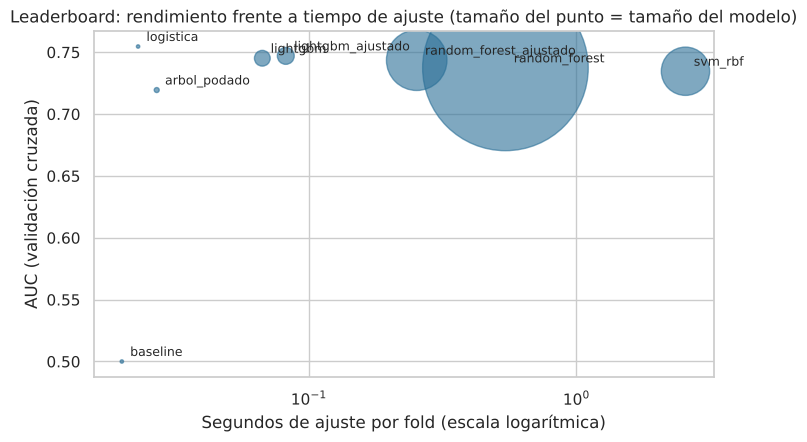

In [9]:
plt.figure(figsize=(8, 4.5))
plt.scatter(lb["seg_ajuste"], lb["auc_cv_media"], s=lb["tamano_kb"].clip(lower=5) * 1.2, alpha=0.6, color="#2a6f97")
for _, f in lb.iterrows():
    plt.annotate(f["modelo"], (f["seg_ajuste"], f["auc_cv_media"]), textcoords="offset points", xytext=(6, 4), fontsize=9)
plt.xscale("log")
plt.title("Leaderboard: rendimiento frente a tiempo de ajuste (tamaño del punto = tamaño del modelo)")
plt.xlabel("Segundos de ajuste por fold (escala logarítmica)")
plt.ylabel("AUC (validación cruzada)")
plt.show()

## 6. Puntuación global con **tus** pesos

**Ejercicio 3.** Define los `pesos` (diccionario con las claves `"rendimiento"`, `"explicabilidad"` y `"coste"`,
que **sumen 1**) que reflejen lo que el cliente valora (por ejemplo, un hotel pequeño que quiere entender el modelo
puede dar más peso a la explicabilidad). Calcula `lb_pond = puntuacion_global(lb, pesos)` y guarda en `campeon`
el nombre del modelo con mayor puntuación.

In [10]:
# Ejercicio 3: pesos acordados con el cliente (rendimiento / explicabilidad / coste)
pesos = {"rendimiento": 0.5, "explicabilidad": 0.3, "coste": 0.2}
lb_pond = puntuacion_global(lb, pesos)
campeon = lb_pond.iloc[0]["modelo"]
assert abs(sum(pesos.values()) - 1) < 1e-9
assert campeon in set(lb["modelo"]) and campeon != "baseline"
print("Campeón con estos pesos:", campeon)
lb_pond[["modelo", "auc_cv_media", "explicabilidad_1a5", "punt_rendimiento", "punt_explicabilidad", "punt_coste", "puntuacion_global"]]

Campeón con estos pesos: logistica


,modelo,auc_cv_media,explicabilidad_1a5,punt_rendimiento,punt_explicabilidad,punt_coste,puntuacion_global
0,logistica,0.7546,4,1.000,0.75,0.974,0.920
6,arbol_podado,0.7194,5,0.862,1.00,0.865,0.904
1,lightgbm_ajustado,0.7470,2,0.970,0.25,0.617,0.684
2,lightgbm,0.7451,2,0.963,0.25,0.608,0.678
3,random_forest_ajustado,0.7435,2,0.956,0.25,0.231,0.599
4,random_forest,0.7373,2,0.932,0.25,0.001,0.541
7,baseline,0.5000,5,0.000,1.00,1.000,0.500
5,svm_rbf,0.7346,1,0.921,0.00,0.000,0.461


> **Análisis de sensibilidad.** ¿Cambia el campeón si cambian los pesos? Prueba tres conjuntos de pesos
> (por ejemplo `0.8/0.1/0.1`, `0.4/0.4/0.2` y `0.2/0.6/0.2`). Si el campeón cambia, **tu recomendación depende de
> lo que valore el cliente**, y así debes contarlo en la *model card*.

In [11]:
escenarios = {"solo rendimiento": {"rendimiento": 0.8, "explicabilidad": 0.1, "coste": 0.1},
              "equilibrado": {"rendimiento": 0.4, "explicabilidad": 0.4, "coste": 0.2},
              "explicabilidad primero": {"rendimiento": 0.2, "explicabilidad": 0.6, "coste": 0.2}}
pd.DataFrame({nombre: [puntuacion_global(lb, p).iloc[0]["modelo"]] for nombre, p in escenarios.items()},
             index=["campeón"]).T

,campeón
solo rendimiento,logistica
equilibrado,arbol_podado
explicabilidad primero,arbol_podado


## 7. El examen final: solo el campeón, una vez

**Ejercicio 4.** Reconstruye el campeón con el diccionario `catalogo` (justo debajo: cada entrada crea el
pipeline de un modelo), ajústalo con **todo `X_train`** y calcula `auc_test_campeon`: su AUC en `X_test`.
Guarda el resultado en el CSV con `actualizar_test(campeon, auc_test_campeon)` y el leaderboard resultante
en `lb_final`. (Si has cambiado hiperparámetros al registrar tus modelos, actualiza también `catalogo`.)

In [12]:
def actualizar_test(nombre, valor):
    """Guarda el AUC de test del campeón en el leaderboard (solo debe llamarse UNA vez)."""
    tabla = pd.read_csv(RUTA_CSV)
    tabla.loc[tabla["modelo"] == nombre, "auc_test"] = round(float(valor), 4)
    tabla.to_csv(RUTA_CSV, index=False)
    return tabla

catalogo = {  # cómo reconstruir cada modelo (ajusta si has cambiado hiperparámetros)
    "logistica": lambda: hacer_pipe(LogisticRegression(max_iter=1000), escalar=True),
    "arbol_podado": lambda: hacer_pipe(DecisionTreeClassifier(min_samples_leaf=80, random_state=SEMILLA)),
    "random_forest": lambda: hacer_pipe(RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEMILLA, n_jobs=2)),
    "lightgbm": lambda: hacer_pipe(lgb.LGBMClassifier(n_estimators=100, learning_rate=0.05, num_leaves=8, random_state=SEMILLA, n_jobs=2, verbose=-1)),
    "svm_rbf": lambda: hacer_pipe(SVC(kernel="rbf", C=1, probability=True, random_state=SEMILLA), escalar=True),
}

In [13]:
# Ejercicio 4: el test se usa UNA vez, solo con el campeón
catalogo["random_forest_ajustado"] = lambda: busqueda_rf.best_estimator_
catalogo["lightgbm_ajustado"] = lambda: busqueda_lgb.best_estimator_
final = catalogo[campeon]().fit(X_train, y_train)
auc_test_campeon = roc_auc_score(y_test, final.predict_proba(X_test)[:, 1])
lb_final = actualizar_test(campeon, auc_test_campeon)
assert 0.65 < auc_test_campeon < 0.85
assert lb_final["auc_test"].notna().sum() == 1
print(f"Campeón: {campeon} · AUC en validación cruzada {lb_pond.iloc[0]['auc_cv_media']:.3f} · AUC en test {auc_test_campeon:.3f}")
lb_final

Campeón: logistica · AUC en validación cruzada 0.755 · AUC en test 0.762


,modelo,familia,auc_cv_media,auc_cv_desv,ap_cv_media,seg_ajuste,ms_pred_1000,tamano_kb,explicabilidad_1a5,notas,auc_test
0,logistica,lineal,0.7546,0.0136,0.7183,0.023,5.0,4.1,4,Coeficientes legibles,0.7623
1,lightgbm_ajustado,ensemble_boosting,0.7470,0.0152,0.7094,0.082,9.0,123.4,2,Búsqueda aleatoria de 20 combinaciones,NaN
2,lightgbm,ensemble_boosting,0.7451,0.0143,0.7062,0.067,11.9,107.2,2,Árboles pequeños en cadena,NaN
3,random_forest_ajustado,ensemble_bagging,0.7435,0.0129,0.6994,0.253,38.8,1581.4,2,Rejilla de 8 combinaciones,NaN
4,random_forest,ensemble_bagging,0.7373,0.0119,0.6916,0.543,47.7,11846.9,2,Muchos árboles votan,NaN
5,svm_rbf,svm,0.7346,0.0118,0.6883,2.557,248.7,1008.7,1,"Caja negra, la más lenta",NaN
6,arbol_podado,arbol,0.7194,0.0095,0.6668,0.027,7.1,10.9,5,Reglas que se leen,NaN
7,baseline,referencia,0.5000,0.0000,0.4590,0.020,4.7,3.1,5,Predice la prevalencia,NaN


## 8. Para la model card: umbral, subgrupos y explicación

El campeón ya está elegido y el test ya se ha usado. Estas celdas **no cambian** la elección: solo describen al campeón con el umbral del Sprint 7 (0,25).

In [14]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score
UMBRAL = 0.25   # el del Sprint 7: sale del coste de una cancelación no prevista frente a una falsa alarma
proba_cv = cross_val_predict(catalogo[campeon](), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
print(f"Validación cruzada (train), umbral {UMBRAL}: recall {recall_score(y_train, proba_cv >= UMBRAL):.2f} · precisión {precision_score(y_train, proba_cv >= UMBRAL):.2f}")
print(f"Tasa de cancelación en train: {y_train.mean():.3f} · en test: {y_test.mean():.3f}")

Validación cruzada (train), umbral 0.25: recall 0.93 · precisión 0.54
Tasa de cancelación en train: 0.459 · en test: 0.459


In [15]:
proba_test = final.predict_proba(X_test)[:, 1]
t = X_test.assign(real=y_test.values, proba=proba_test, aviso=(proba_test >= UMBRAL).astype(int))
def resumen(g):
    return pd.Series({"reservas": len(g), "cancela_real": g["real"].mean(), "avisadas": g["aviso"].mean(),
                      "AUC": roc_auc_score(g["real"], g["proba"]) if g["real"].nunique() > 1 else np.nan})
por_canal = t.groupby("canal").apply(resumen, include_groups=False).round(3)
por_pais = t.groupby("pais_origen").apply(resumen, include_groups=False).round(3)
print(por_canal); print(); print(por_pais)

                   reservas  cancela_real  avisadas    AUC
canal                                                     
agencia               226.0         0.456     0.765  0.725
directo               300.0         0.273     0.563  0.758
empresa                67.0         0.448     0.776  0.718
web_intermediaria     607.0         0.554     0.908  0.741

             reservas  cancela_real  avisadas    AUC
pais_origen                                         
DE              194.0         0.448     0.794  0.710
ES              293.0         0.485     0.788  0.772
FR               45.0         0.511     0.667  0.852
IT               64.0         0.422     0.781  0.742
NL               62.0         0.403     0.823  0.721
Nordicos         87.0         0.494     0.793  0.795
UK              302.0         0.464     0.801  0.763
otros           123.0         0.390     0.772  0.796


In [16]:
nombres = final.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(final.named_steps["clf"].coef_[0], index=nombres).sort_values()
odds = np.exp(coefs).round(2)
print("Reducen el riesgo (odds ratio < 1):"); print(odds.head(5).to_string())
print("\nAumentan el riesgo (odds ratio > 1):"); print(odds.tail(5).iloc[::-1].to_string())

Reducen el riesgo (odds ratio < 1):
cat__deposito_total              0.43
cat__canal_directo               0.54
cat__tarifa_no_reembolsable      0.60
num__precio_noche                0.71
cat__tipo_habitacion_estandar    0.78

Aumentan el riesgo (odds ratio > 1):
num__antelacion_dias            2.14
cat__deposito_sin_deposito      1.87
cat__canal_web_intermediaria    1.62
cat__tarifa_flexible            1.34
num__temporada_alta             1.30


In [17]:
import sys, sklearn, xgboost, lightgbm
print("Python", sys.version.split()[0])
print("scikit-learn", sklearn.__version__)
print("xgboost", xgboost.__version__)
print("lightgbm", lightgbm.__version__)
print("pandas", pd.__version__, "· SEMILLA", SEMILLA)

Python 3.13.18
scikit-learn 1.9.1
xgboost 3.3.0
lightgbm 4.7.0
pandas 2.3.3 · SEMILLA 42
